# 02 · Exploring the clean data with charts

**EDA** (exploratory data analysis) means looking at the data before modelling it.
The aim is to find out what the model will be up against: how popularity is spread out,
which features move with it, and how much genre matters.

We use `tracks_clean`, the table built by `python -m src.db` (76,569 songs, one row each).

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DB_PATH = Path("..") / "data" / "spotify.db"
with sqlite3.connect(DB_PATH) as conn:
    df = pd.read_sql("SELECT * FROM tracks_clean", conn)

df.shape

(76569, 20)

A shared chart style so every chart looks the same: thin marks, light grid, no box around the plot,
grey text for labels. The colours are a palette checked for colour-blind readers.

In [2]:
INK = "#0b0b0b"
INK_2 = "#52514e"
GRID = "#e4e3df"
SURFACE = "#fcfcfb"
BLUE = "#2a78d6"   # main colour; also the 'positive' end
RED = "#e34948"    # 'negative' end

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 10,
    "figure.dpi": 110,
})

## 1. How is popularity spread out?

A **histogram** cuts the 1-100 range into bins and counts how many songs fall in each.
Tall bars = common scores.

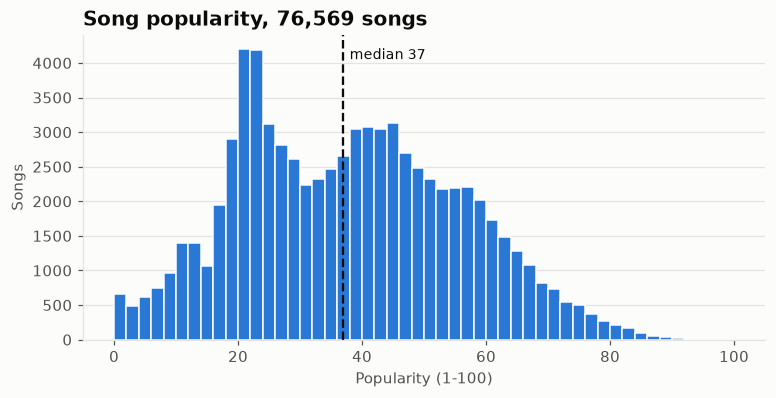

count    76569.0
mean        37.4
std         17.8
min          1.0
25%         23.0
50%         37.0
75%         50.0
max        100.0
Name: popularity, dtype: float64

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(df["popularity"], bins=range(0, 102, 2), color=BLUE, edgecolor=SURFACE, linewidth=1)
ax.axvline(df["popularity"].median(), color=INK, linewidth=1.5, linestyle="--")
ax.text(df["popularity"].median() + 1, ax.get_ylim()[1] * 0.92,
        f"median {df['popularity'].median():.0f}", color=INK, fontsize=9)
ax.set_title("Song popularity, 76,569 songs")
ax.set_xlabel("Popularity (1-100)")
ax.set_ylabel("Songs")
ax.grid(axis="x", visible=False)
plt.show()

df["popularity"].describe().round(1)

**How to read it:** most songs sit between about 20 and 55; half are above 37 (the **median**, the middle value).
Very few songs pass 80. There's also an odd spike around 20-23 that we can't explain from this data alone;
it may be a quirk of how the dataset was collected. A model that always guessed 37 would already be close for many songs,
which is why we'll use "always guess the average" as the baseline to beat in step 5.

## 2. Which audio features move with popularity?

**Correlation** is a number from -1 to +1:
- **+1**: when one goes up, the other always goes up.
- **0**: no straight-line link.
- **-1**: when one goes up, the other always goes down.

Blue bars = positive, red = negative.

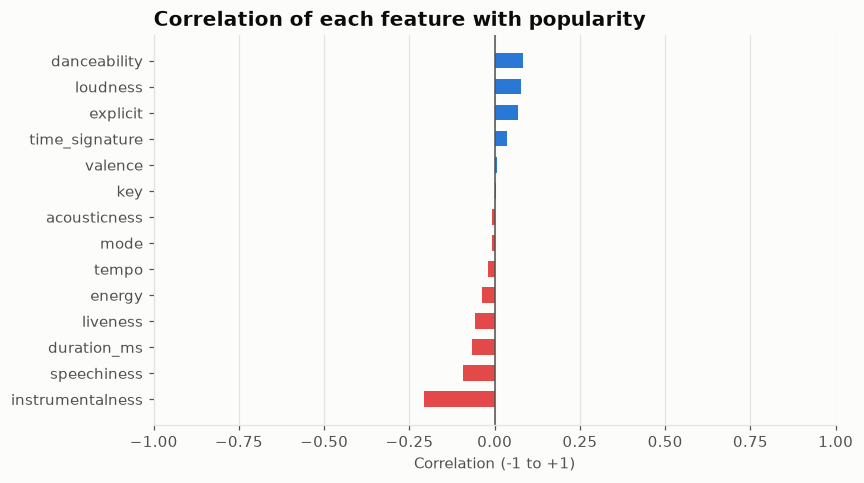

instrumentalness   -0.207
speechiness        -0.091
duration_ms        -0.066
liveness           -0.058
energy             -0.036
tempo              -0.019
mode               -0.008
acousticness       -0.007
key                 0.003
valence             0.005
time_signature      0.035
explicit            0.068
loudness            0.078
danceability        0.083
Name: popularity, dtype: float64

In [4]:
features = ["danceability", "energy", "loudness", "speechiness", "acousticness",
            "instrumentalness", "liveness", "valence", "tempo", "duration_ms",
            "explicit", "mode", "key", "time_signature"]
corr = df[features + ["popularity"]].corr()["popularity"].drop("popularity").sort_values()

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(corr.index, corr.values, color=[RED if v < 0 else BLUE for v in corr.values], height=0.6)
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_xlim(-1, 1)
ax.set_title("Correlation of each feature with popularity")
ax.set_xlabel("Correlation (-1 to +1)")
ax.grid(axis="y", visible=False)
plt.show()

corr.round(3)

**How to read it:** with the axis drawn from -1 to +1, every bar is tiny. The strongest is
`instrumentalness` at about -0.21 (songs without vocals are a bit less popular).
**No single audio feature predicts popularity well on its own.** That's an honest early warning:
don't expect a near-perfect model.

## 3. But correlation only sees straight lines

Correlation measures straight-line links. A feature can matter in a curved way and still score near 0.
Here each feature is cut into 10 equal slices, and we plot the average popularity in each slice.

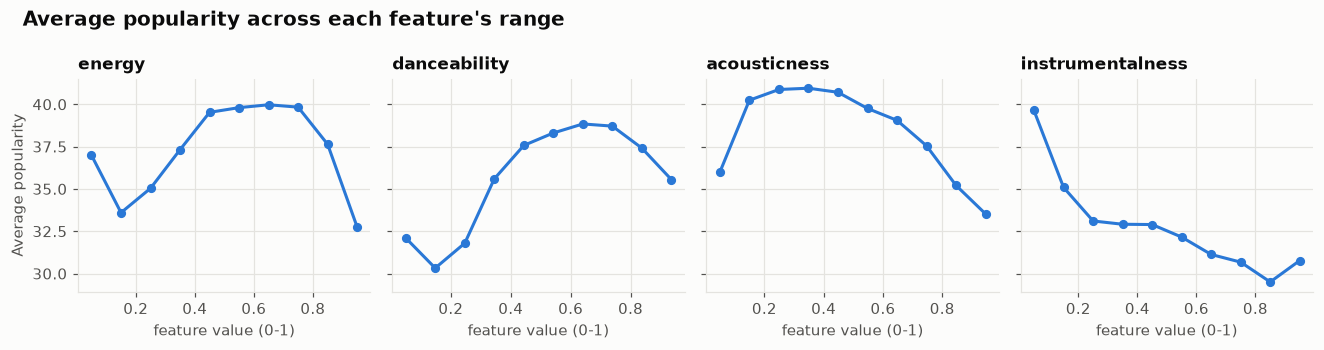

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for ax, feature in zip(axes, ["energy", "danceability", "acousticness", "instrumentalness"]):
    slices = pd.cut(df[feature], 10)
    avg = df.groupby(slices, observed=True)["popularity"].mean()
    mids = [interval.mid for interval in avg.index]
    ax.plot(mids, avg.values, color=BLUE, linewidth=2, marker="o", markersize=5)
    ax.set_title(feature, fontsize=11)
    ax.set_xlabel("feature value (0-1)")
axes[0].set_ylabel("Average popularity")
fig.suptitle("Average popularity across each feature's range", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
plt.show()

**Careful:** the y-axis runs from about 30 to 40, not from 0, so these changes look bigger than they are.
A swing of 7 points is real but modest on a 1-100 scale. Always check where an axis starts.

**How to read it:** `energy` rises, flattens around 40, then **drops** for the most intense songs.
That's a hump, and its correlation (-0.04) completely hides it. Linear Regression only draws straight lines,
so it will miss shapes like this; tree models (Random Forest, LightGBM) can follow them.
This is the main reason we expect trees to win in step 5.

## 4. Genre matters a lot

114 genres won't fit on one readable chart, so here are the 10 lowest and 10 highest by average popularity.

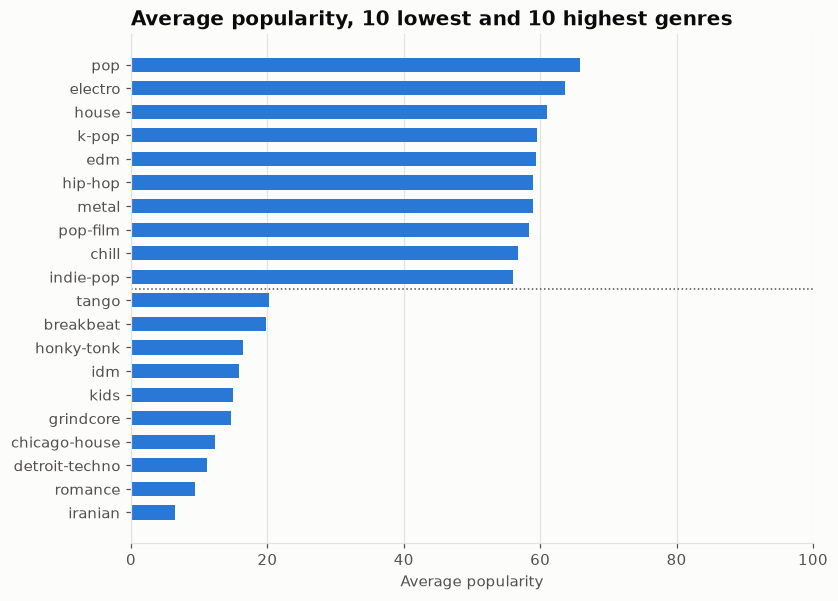

,mean,count
track_genre,,
iranian,6.5,336
romance,9.4,333
detroit-techno,11.2,939
chicago-house,12.4,926
grindcore,14.7,970
kids,15.0,917
idm,15.9,950
honky-tonk,16.4,825
breakbeat,19.8,928


In [6]:
by_genre = df.groupby("track_genre")["popularity"].agg(["mean", "count"]).sort_values("mean")
ends = pd.concat([by_genre.head(10), by_genre.tail(10)])

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(ends.index, ends["mean"], color=BLUE, height=0.6)
ax.axhline(9.5, color=INK_2, linewidth=1, linestyle=":")
ax.set_title("Average popularity, 10 lowest and 10 highest genres")
ax.set_xlabel("Average popularity")
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
plt.show()

ends.round(1)

How much of the ups and downs in popularity does genre explain **on its own**?
We guess each song's popularity as its genre's average, and measure how much of the variation that captures
(this number is called **R²**: 0 = explains nothing, 1 = explains everything).

In [7]:
genre_average = df.groupby("track_genre")["popularity"].transform("mean")
overall_average = df["popularity"].mean()

unexplained = ((df["popularity"] - genre_average) ** 2).sum()
total = ((df["popularity"] - overall_average) ** 2).sum()
r2_genre_only = 1 - unexplained / total
round(r2_genre_only, 3)

np.float64(0.487)

**About half (0.49)** of the variation is explained by genre alone, far more than any audio feature.
Two cautions:
- This is measured on the same songs the averages came from, so it's a bit optimistic. Step 5 measures on unseen songs.
- Genre was picked at random for songs listed under several genres (our cleaning choice), which adds some noise.

## Your turn: three findings

Write three findings in plain words, as if explaining to a friend who has never seen this data.
One sentence each, and include a number where you can. Edit this cell (double-click it).

1. the genre matters a lot because it can influence by the trends going around, lets say tiktok trends mostly comes with a song from the genre of pop or hiphop
2. song feature also important as you want the song to be good to listen, people dont a song that is just sounds or just talking or a song that is super long.
3. the variation shows that in other to predict a song popularity, a genre is a very important aspect to take a big consideration at.

### Revised versions (what I saw, the number, what it means)

1. Genre makes a big difference: pop songs average 66 popularity while iranian songs average 6.5. (My guess, not tested: trends like TikTok favour pop and hip-hop.)
2. Songs that are mostly instrumental, mostly spoken, or very long tend to be slightly less popular, but the links are weak (the strongest is -0.21 on a -1 to +1 scale), so no single sound feature predicts popularity well.
3. Some features matter in a curved way that correlation misses: popularity rises with energy, then drops for the most intense songs, so I expect tree models to beat a straight-line model.